In [1]:
# ============================================================
# SMART LOAN APPROVAL SYSTEM USING ML AND DMN
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression


In [2]:
# ============================================================
# 1. TRAINING DATA
# ============================================================

data = {
    "Income": [
        25000, 30000, 35000, 40000,
        45000, 50000, 60000, 70000,
        80000, 90000, 100000, 120000
    ],

    "CreditScore": [
        550, 580, 600, 620,
        650, 670, 700, 720,
        750, 780, 800, 820
    ],

    "DefaultStatus": [
        1, 1, 1, 0,
        1, 0, 0, 0,
        0, 0, 0, 0
    ]
}

df = pd.DataFrame(data)



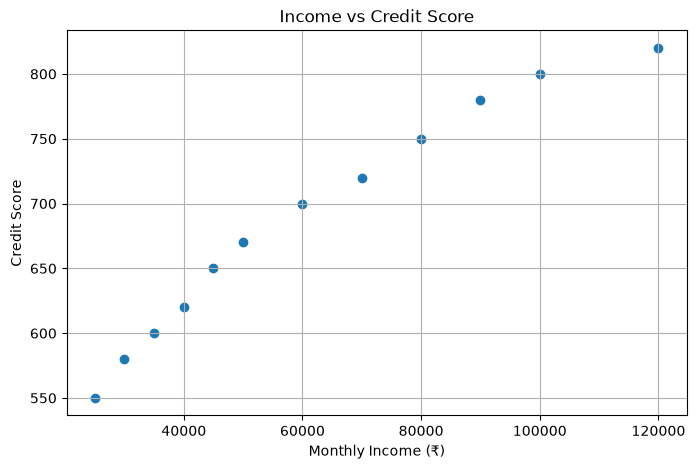

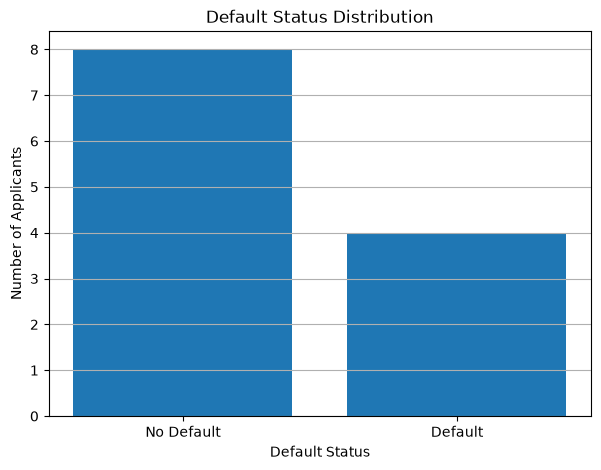

In [3]:
# ============================================================
# 2. DATA VISUALIZATION - TRAINING DATA
# ============================================================

# ------------------------------------------------------------
# Visualization 1: Income vs Credit Score
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Income"],
    df["CreditScore"]
)

plt.xlabel("Monthly Income (₹)")
plt.ylabel("Credit Score")
plt.title("Income vs Credit Score")
plt.grid(True)

plt.show()


# ------------------------------------------------------------
# Visualization 2: Default Status Distribution
# ------------------------------------------------------------

default_counts = df["DefaultStatus"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["No Default", "Default"],
    [
        default_counts.get(0, 0),
        default_counts.get(1, 0)
    ]
)

plt.xlabel("Default Status")
plt.ylabel("Number of Applicants")
plt.title("Default Status Distribution")
plt.grid(axis="y")

plt.show()


In [4]:
# ============================================================
# 3. TRAIN MACHINE LEARNING MODEL
# ============================================================

# Features
X = df[["Income", "CreditScore"]]

# Target
y = df["DefaultStatus"]

# Create Logistic Regression model
model = LogisticRegression()

# Train model
model.fit(X, y)


print("\n======================================")
print("   SMART LOAN APPROVAL SYSTEM")
print("======================================")




   SMART LOAN APPROVAL SYSTEM


In [5]:
# ============================================================
# 4. DMN DECISION FUNCTION
# ============================================================

def dmn_decision(risk_score, income, age):

    # Rule 1: High Risk
    if risk_score >= 0.70:

        return {
            "Status": "Rejected",
            "InterestRate": "N/A",
            "Rule": "High Risk"
        }

    # Rule 2: Young + Low Income
    elif age < 21 and income < 30000:

        return {
            "Status": "Manual Review",
            "InterestRate": "12%",
            "Rule": "Young Applicant + Low Income"
        }

    # Rule 3: Medium Risk
    elif 0.40 <= risk_score < 0.70:

        return {
            "Status": "Manual Review",
            "InterestRate": "10%",
            "Rule": "Medium Risk"
        }

    # Rule 4: Low Risk + Good Income
    elif risk_score < 0.40 and income >= 50000:

        return {
            "Status": "Approved",
            "InterestRate": "7%",
            "Rule": "Low Risk + Good Income"
        }

    # Rule 5: Low Risk + Lower Income
    elif risk_score < 0.40 and income < 50000:

        return {
            "Status": "Approved",
            "InterestRate": "9%",
            "Rule": "Low Risk + Lower Income"
        }

    # Default rule
    else:

        return {
            "Status": "Manual Review",
            "InterestRate": "10%",
            "Rule": "Default Rule"
        }



In [6]:
# ============================================================
# 5. USER INPUT
# ============================================================

print("\nEnter Applicant Details")

income = float(
    input("Monthly Income (₹): ")
)

credit_score = float(
    input("Credit Score: ")
)

age = int(
    input("Age: ")
)




Enter Applicant Details


In [7]:
# ============================================================
# 6. ML PREDICTION
# ============================================================

applicant = pd.DataFrame({
    "Income": [income],
    "CreditScore": [credit_score]
})


# Probability of Default
default_probability = model.predict_proba(
    applicant
)[0][1]


# RiskScore
risk_score = default_probability



In [8]:
# ============================================================
# 7. DMN DECISION
# ============================================================

decision = dmn_decision(
    risk_score,
    income,
    age
)


In [9]:
# ============================================================
# 8. DISPLAY ML RESULT
# ============================================================

print("\n======================================")
print("             ML RESULT")
print("======================================")

print(
    f"Risk Score: {risk_score:.2f}"
)

print(
    f"Default Probability: {risk_score * 100:.2f}%"
)



             ML RESULT
Risk Score: 0.00
Default Probability: 0.00%


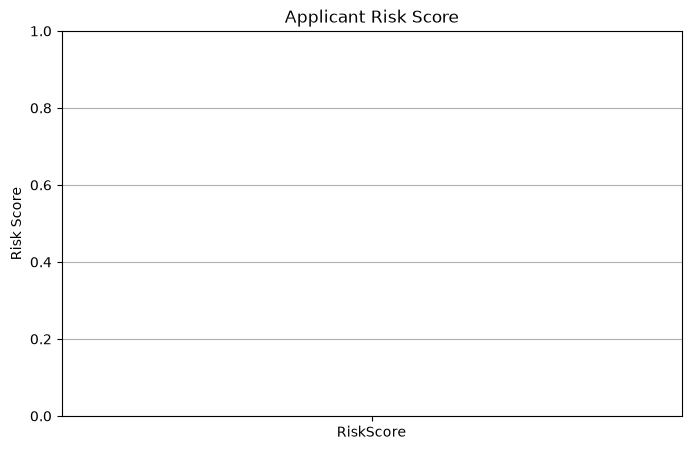

In [10]:
# ============================================================
# 9. VISUALIZE APPLICANT RISK SCORE
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["RiskScore"],
    [risk_score]
)

plt.ylim(0, 1)

plt.ylabel("Risk Score")
plt.title("Applicant Risk Score")

plt.grid(axis="y")

plt.show()

In [11]:


# ============================================================
# 10. DISPLAY DMN RESULT
# ============================================================

print("\n======================================")
print("             DMN RESULT")
print("======================================")

print(
    f"Status: {decision['Status']}"
)

print(
    f"Offered Interest Rate: "
    f"{decision['InterestRate']}"
)

print(
    f"Decision Rule: "
    f"{decision['Rule']}"
)


             DMN RESULT
Status: Approved
Offered Interest Rate: 7%
Decision Rule: Low Risk + Good Income


In [12]:


# ============================================================
# 11. FINAL DECISION
# ============================================================

print("\n======================================")
print("         FINAL LOAN DECISION")
print("======================================")


if decision["Status"] == "Approved":

    print("Loan Approved!")
    print(
        f"Interest Rate: "
        f"{decision['InterestRate']}"
    )

elif decision["Status"] == "Rejected":

    print("Loan Rejected.")

else:

    print("Loan requires Manual Review.")

    print(
        f"Suggested Interest Rate: "
        f"{decision['InterestRate']}"
    )


print("======================================")


         FINAL LOAN DECISION
Loan Approved!
Interest Rate: 7%
